# Como se ve el cirrus en los L2W de ACOLITE

Tres escenas con distinta cantidad de cirrus (bit 2 de `l2_flags`), para ver que esta marcando la bandera.
En el L2W los pixeles con cirrus/nube salen en NaN (no se ve nada), asi que las imagenes salen del L2R (`rhot` = reflectancia en el tope de la atmosfera, antes de la correccion).
Para cada una: color natural con `rhot` (B04-B03-B02), la banda de cirrus `rhot_1373` (el cirrus brilla ahi y el suelo/agua no), la mascara de `l2_flags` y los puntos de matchup.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))

from viz.acolite import visualizar_cirrus

import geopandas as gpd
import xarray as xr

DATA = ROOT / "data"
MATCHUPS_FILE = DATA / "nuevos" / "matchups_registros_finales.geojson"

escenas = {
    "ralo, parcial (27% cirrus)": "S2B_MSIL1C_20170804T134209_N0500_R124_T21HXB_20230916T125616",
    "mixto (44% cirrus, 22% muy brillante)": "S2C_MSIL1C_20250506T133211_N0511_R081_T21HXB_20250506T151040",
    "toda la escena marcada (100% cirrus, 54% muy brillante)": "S2A_MSIL1C_20200515T134221_N0500_R124_T21HXB_20230403T155612",
}

matchups = gpd.read_file(MATCHUPS_FILE).to_crs("EPSG:4326")
matchups["lon"] = matchups.geometry.x
matchups["lat"] = matchups.geometry.y

In [2]:
def abrir(pass_id, nivel):
    path = next((DATA / "acolite" / pass_id).glob(f"**/*{nivel}.nc"))
    return xr.open_dataset(path).load()


ralo, parcial (27% cirrus) S2B_MSIL1C_20170804T134209_N0500_R124_T21HXB_20230916T125616
  buenos 24.2%   cirrus 26.9%   muy brillante 4.7%   cirrus sin muy brillante 23.7%
  rhot_1373: mediana con cirrus 0.007  /  sin cirrus 0.003


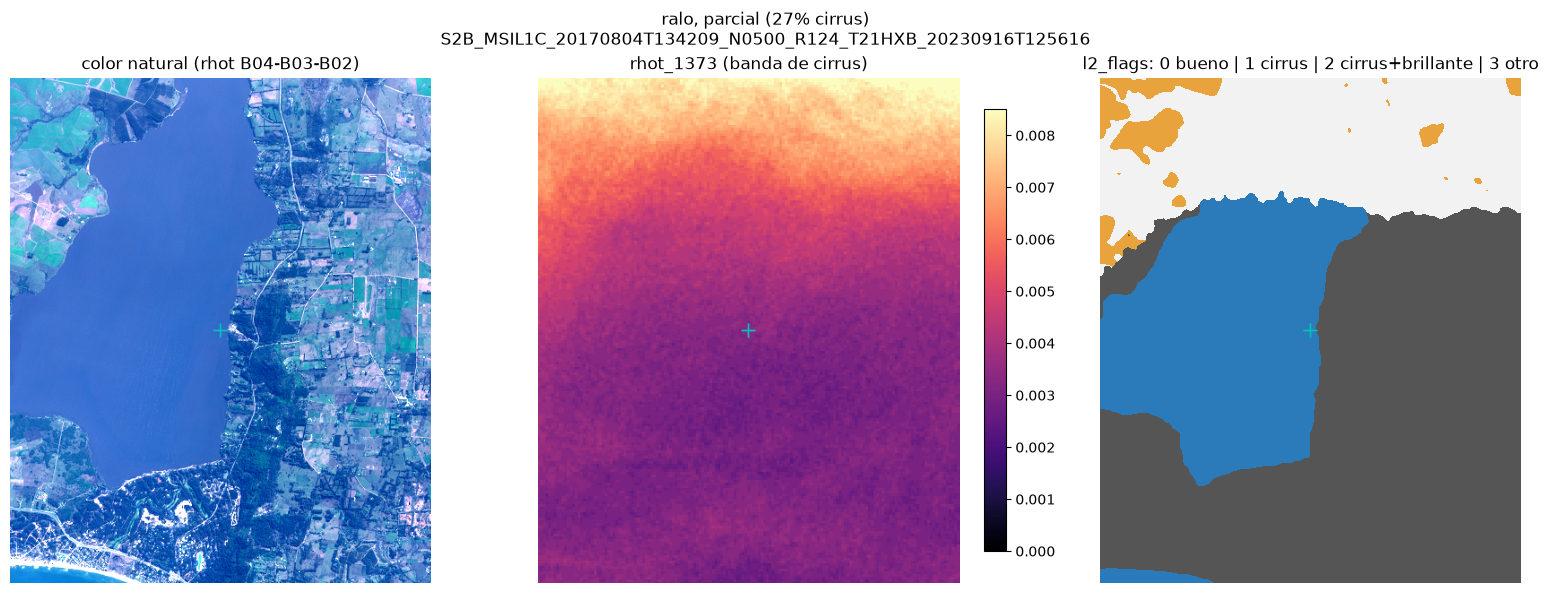

mixto (44% cirrus, 22% muy brillante) S2C_MSIL1C_20250506T133211_N0511_R081_T21HXB_20250506T151040
  buenos 16.4%   cirrus 44.1%   muy brillante 21.8%   cirrus sin muy brillante 33.1%
  rhot_1373: mediana con cirrus 0.007  /  sin cirrus 0.004


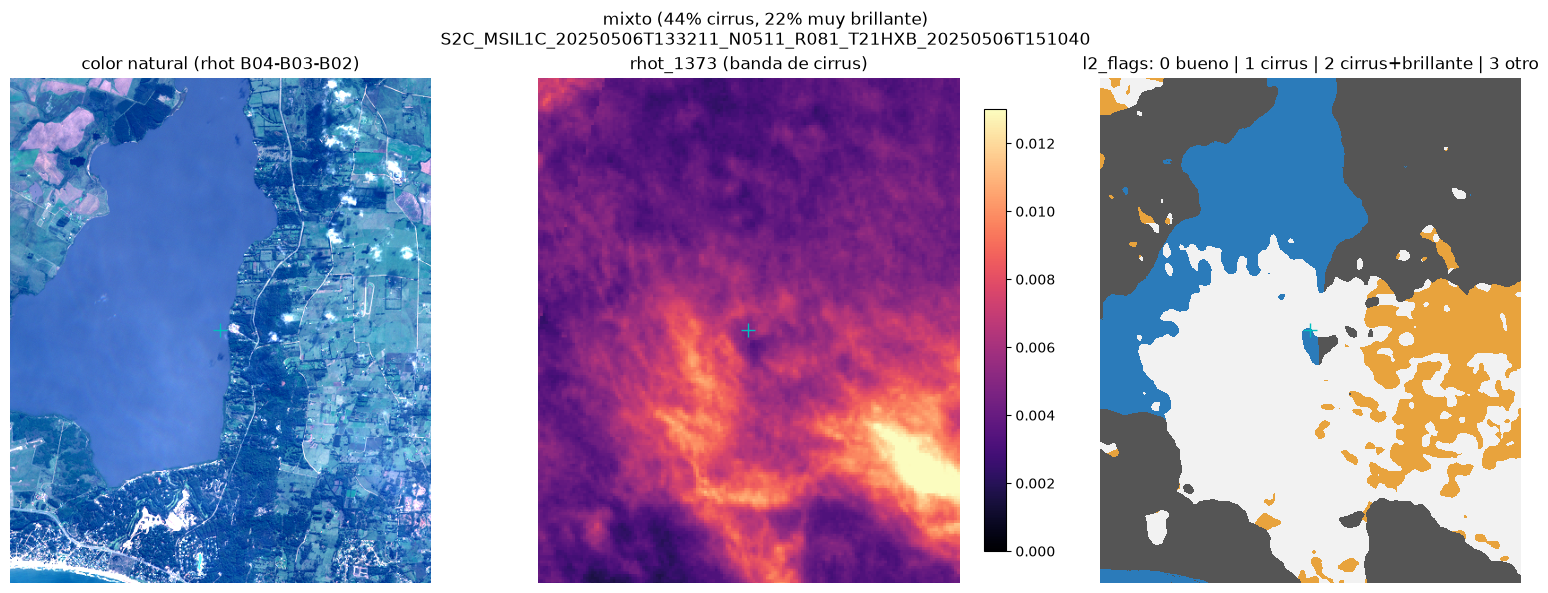

toda la escena marcada (100% cirrus, 54% muy brillante) S2A_MSIL1C_20200515T134221_N0500_R124_T21HXB_20230403T155612
  buenos 0.0%   cirrus 100.0%   muy brillante 53.9%   cirrus sin muy brillante 46.1%
  rhot_1373: mediana con cirrus 0.015  /  sin cirrus nan


/home/enzotrindade/ProyectoAA/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


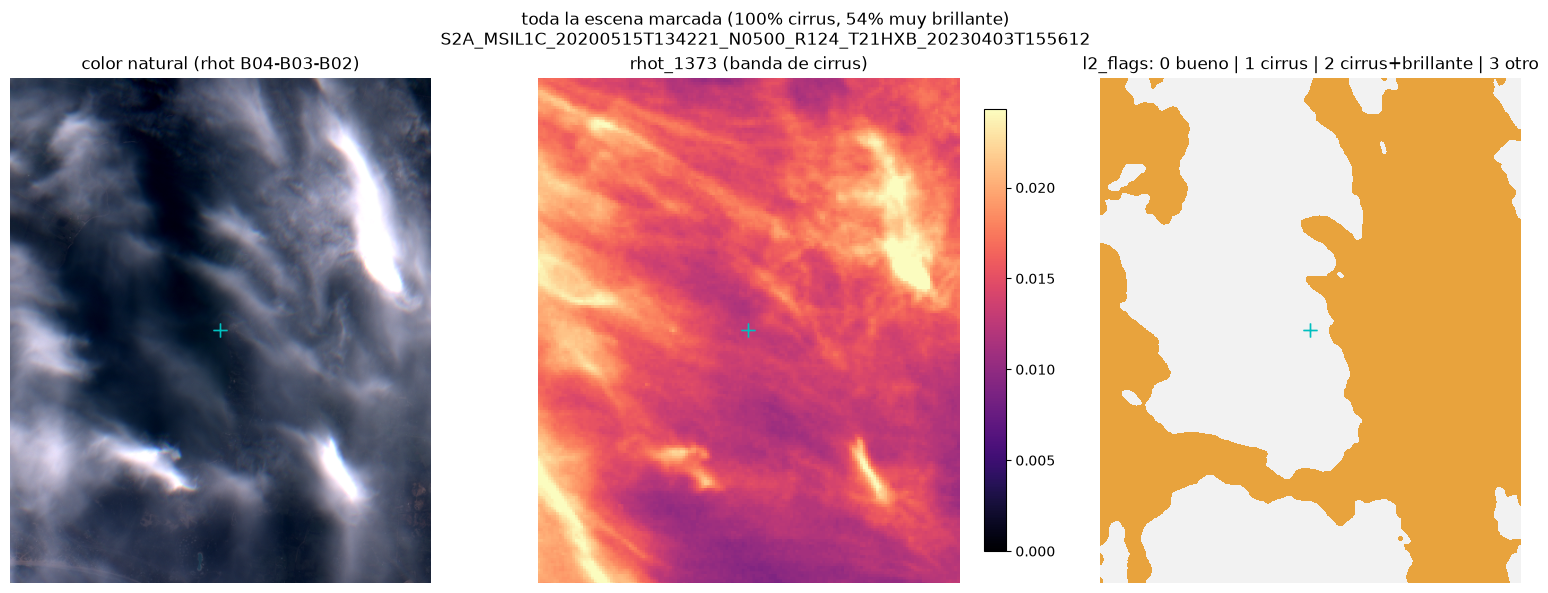

In [3]:
for titulo, pass_id in escenas.items():
    dl = abrir(pass_id, "L2R")
    w = abrir(pass_id, "L2W")
    pts = matchups[matchups["pass_id"] == pass_id]
    visualizar_cirrus(dl, w, pts, titulo=titulo, pass_id=pass_id)
